<a href="https://colab.research.google.com/github/raisa1521/Deep-Learning-PyTorch-Textbook/blob/main/2%EC%9E%A5_%EC%8B%A4%EC%8A%B5%ED%99%98%EA%B2%BD%EC%84%A4%EC%A0%95%EA%B3%BC_%ED%8C%8C%EC%9D%B4%ED%86%A0%EC%B9%98_%EA%B8%B0%EC%B4%88.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 2. 실습 환경 설정과 파이토치 기초

2.1 파이토치 개요

2.2 파이토치 기초 문법

2.3 실습 환경 설정

2.4 파이토치 코드 맛보기

## 2.1 파이토치 개요

파이썬 기반의 과학 연산 패키지로 다음 두 집단을 대상으로 함.

- 넘파이를 대체하면서 GPU를 이용한 연산이 필요한 경우
- 최대한의 유연성과 속도를 제공하는 딥러닝 연구 플랫폼이 필요한 경우

간결하고 빠른 구현성이 가장 큰 사용 이유

### 2.1.1 파이토치 특징 및 장점


**GPU에서 텐서 조작 및 동적 신경망 구축이 가능한 프레임워크**


**GPU**: 연산 속도를 빠르게 하는 역할
 - 딥러닝에서는 기울기를 계산할 때 미분을 쓰는데 GPU를 사용하면 빠른 계산이 가능
 - 내부적으로 CUDA, cuDNN이라는 API를 통해 GPU를 연산에 사용할 수 있음
 - 병렬 연산에서 GPU의 속도는 CPU의 속도보다 훨씬 빠르므로 딥러닝 학습에서 GPU 사용은 필수

**텐서**: 파이토치의 데이터 형태
 - 단일 데이터 형식으로 된 자료들의 다차원 행렬
 - 명령어(변수 뒤에 .cuda()를 추가)를 사용해서 GPU로 연산을 수행하게 할 수 있음

**동적 신경망**: 훈련을 반복할 때마다 네트워크 변경이 가능한 신경망.
 - 예를 들어 학습 중에 은닉층을 추가하거나 제거하는 등 모델의 네트워크 조작이 가능
 - 연산 그래프를 정의하는 것과 동시에 값도 초기화되는 Define by Run 방식을 사용 -> 연산 그래프와 연산을 분리해서 생각할 필요가 없기 때문에 코드를 이해하기 쉬움


인공지능(머신 러닝/딥러닝)에서 데이터는 벡터(vector)로 표현됨

- 1차원 축(행)=axis 0=벡터
- 2차원 축(열)=axis 1=행렬
- 3차원 축(채널)=axis 2=텐서

In [1]:
import torch
torch.tensor([[1., -1.], [1., -1.]])

tensor([[ 1., -1.],
        [ 1., -1.]])

연산 그래프는 방향성이 있으며 변수(텐서)를 의미하는 노드와 연산을 담당하는 엣지로 구성됨.

신경망은 연산 그래프를 이용하여 계산을 수행함. 즉, 네트워크가 학습될 때 손실 함수의 기울기가 가중치와 바이어스를 기반으로 계산되며, 이후 경사 하강법을 사용하여 가중치가 업데이트 됨. 이때 연산 그래프를 이용하여 이 과정이 효과적으로 수행됨

파이토치는 효율적인 계산, 낮은 CPU 활용, 직관적인 인터페이스와 낮은 진입 장벽이 장점임

**효율적인 계산**
- 파이썬 환경과 쉽게 통합할 수 있습니다.
- 디버깅이 직관적이고 간결

**낮은 CPU 활용**
- 모델 훈련을 위한 CPU 사용률이 텐서플로와 비교하여 낮음
- 학습 및 추론 속도가 빠르고 다루기 쉬움.

**직관적인 인터페이스**
- 텐서플로처럼 잦은 API 변경(layers → slim → estimators → tf.keras)이 없어 배우기 쉬움



### 2.1.2 파이토치의 아키텍처

파이토치의 아키텍처는 간단함. 크게 세 개의 계층으로 나누어 설명 가능

- 가장 상위 계층 : 파이토치 API

- 중간 : 파이토치 엔진(다차원 텐서 및 자동 미분을 처리)

- 가장 아래 : 텐서에 대한 연산을 처리

 CPU/GPU를 이용하는 텐서의 실질적인 계산을 위한 C, CUDA 등 라이브러리가 위치

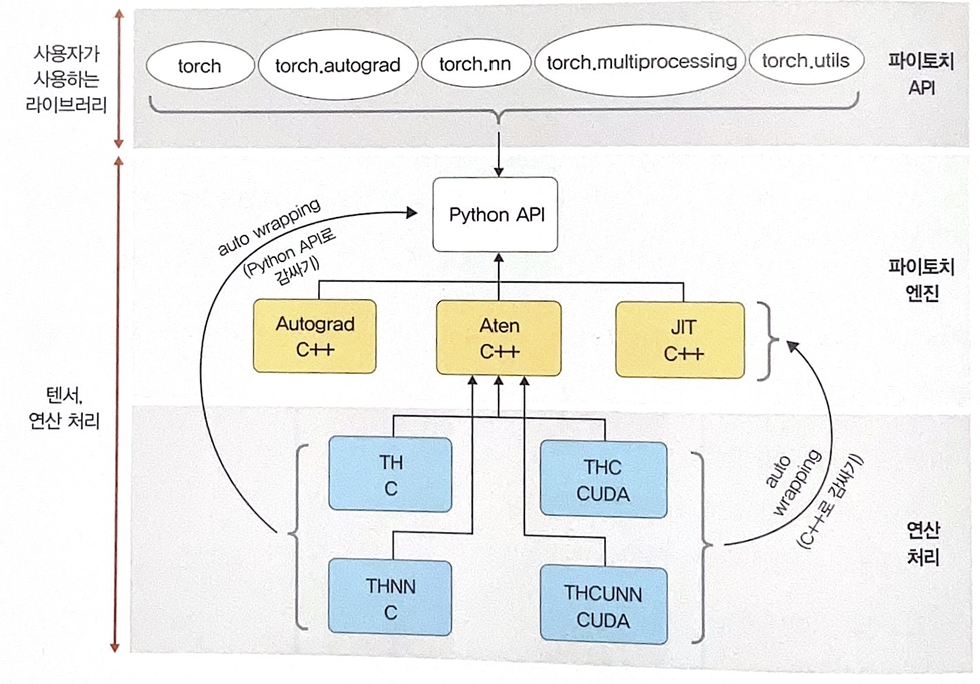

#### **<파이토치 API>**

 이해하기 쉬운 API를 제공해서 텐서에 대한 처리와 신경망을 구축하고 훈련할 수 있도록 도움. 이 계층에서는 사용자 인터페이스를 제공하지만 실제 계산은 수행X. 대신 C++로 작성된 파이토치 엔진으로 그 작업을 전달하는 역할만 함.

파이토치 API 계층에서는 사용자의 편의성을 위해 다음 패키지들이 제공됨.

**torch: GPU를 지원하는 텐서 패키지**

다차원 텐서를 기반으로 다양한 수학적 연산이 가능. CPU뿐만 아니라 GPU에서 연산이 가능하므로 빠른 속도로 많은 양의 계산 가능

**torch.autograd: 자동 미분 패키지**

일반적으로 신경망에 사소한 변경(ex 은닉층 노드 수 변경)이 있다면 신경망 구축을 처음부터 다시 시작해야 함. 파이토치는 자동 미분 기술을 채택하여 미분 계산을 효율적으로 처리.

-연산 그래프가 즉시 계산되기 때문에 사용자는 다양한 신경망을 적용 가능

**torch.nn: 신경망 구축 및 훈련 패키지**

torch.nn을 사용할 경우 신경망을 쉽게 구축하고 사용가능. 특히 합성곱 신경망, 순환 신경망, 정규화 등이 포함되어 손쉽게 신경망을 구축하고 학습 가능

**torch.multiprocessing: 파이썬 멀티프로세싱 패키지**

파이토치에서 사용하는 프로세스 전반에 걸쳐 텐서의 메모리 공유가 가능. 서로 다른 프로세스에서 동일한 데이터(텐서)에 대한 접근 및 사용 가능

**torch.utils: DataLoader 및 기타 유틸리티를 제공하는 패키지**


#### **<파이토치 엔진>**